# Logistic Regression (Binary Classification) — One Variable

## Project idea & discussion

Picture the same restaurant-chain owner from the linear-regression series. Last time he wanted to know **how much profit** a new branch would make. This time his question is simpler, but arguably more important for the go/no-go decision: **will this branch be "successful" or not?**

We define a branch as **successful** if its `Profit` is greater than or equal to some `Threshold`. In the spreadsheet we set that threshold to `5` (i.e. $50,000) as an example — it's stored in a cell in the Excel file, so you can change it and see how the results shift.

We'll use **Logistic Regression** to classify each city — based only on its population — into:

- **Class 1** → the branch is expected to be successful (`Profit >= Threshold`)
- **Class 0** → the branch is expected to be unsuccessful (`Profit < Threshold`)

| Symbol | Meaning |
|---|---|
| $x$ | City population (in units of 10,000) |
| $y \in \{0,1\}$ | The class (1 = successful, 0 = not successful) |
| $m$ | Number of training examples (cities) |
| $\theta_0, \theta_1$ | Model parameters we'll learn |
| $h_\theta(x)$ | Probability that $y=1$ given $x$ |

**Why not just reuse linear regression?** In linear regression we predicted a continuous number (the profit itself). Here we want to predict a **category** (success / not success). If we tried to fit a straight line to 0/1 labels directly, the line could shoot below 0 or above 1 — which makes no sense as a probability, and it's also very sensitive to outliers on the x-axis. Logistic regression fixes this by squashing the linear combination of inputs through a function that always outputs something between 0 and 1 (a probability), and *then* turning that probability into a hard decision.

## 1. Import libraries

Nothing new here — `numpy` for the math/vectorized operations, `pandas` to load and inspect the spreadsheet, and `matplotlib` to visualize the data and the fitted curve.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
%matplotlib inline


## 2. Load and explore the data

The data lives in `classification_data.xlsx` — a sheet with 3 columns: `Population`, `Profit`, and `Label`. The `Label` column was computed *inside Excel* with a formula like `=IF(Profit>=Threshold,1,0)`, so the labeling logic is transparent and easy to tweak by just changing the threshold cell.

**Talking point:** notice we're checking the **class balance** below (`value_counts`). This matters a lot in classification — if 95% of cities were "successful," a model that always predicts "successful" would already look 95% accurate while being useless. Always check this before trusting an accuracy number.

In [2]:
try:
    from google.colab import files
    import io
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    df = pd.read_excel(io.BytesIO(uploaded[fname]))
except ImportError:
    df = pd.read_excel('classification_data.xlsx')

df = df.iloc[:, :3]
df.columns = ['Population', 'Profit', 'Label']
m = len(df)
print(f'Number of examples (m) = {m}')
print('Class balance:')
print(df['Label'].value_counts())
df.head()


Number of examples (m) = 97
Class balance:
Label
0    52
1    45
Name: count, dtype: int64


,Population,Profit,Label
0,6.1101,17.5920,1
1,5.5277,9.1302,1
2,8.5186,13.6620,1
3,7.0032,11.8540,1
4,5.8598,6.8233,1


## 3. Plot the data

We plot every city as a point along the population axis, colored by its class: success (1) or failure (0). This lets us visually sanity-check whether there's a reasonable separation between the two classes before we even fit a model.

**Talking point:** if the two classes were hopelessly mixed together (green and red dots scattered everywhere with no pattern), that would be a signal that population alone isn't a good predictor, and we'd need more features. Here, we're hoping to see the red points (Class 0) clustered toward lower populations and green points (Class 1) toward higher ones.

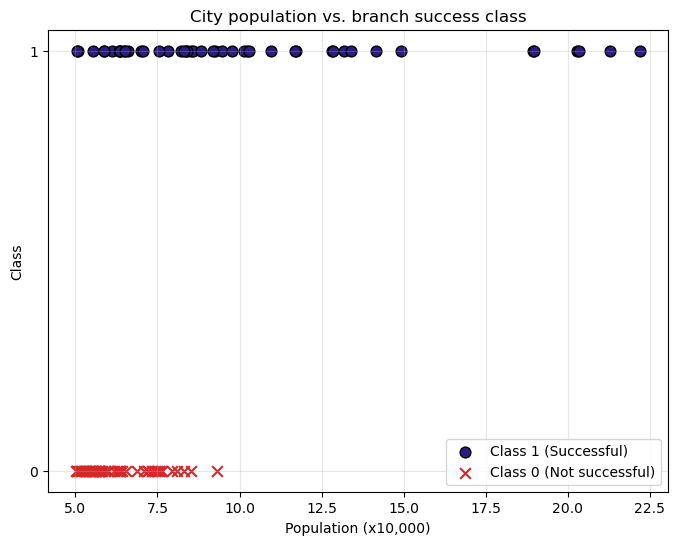

In [4]:
X_raw = df['Population'].values
y = df['Label'].values.astype(int)

plt.figure(figsize=(8,6))
plt.scatter(X_raw[y==1], np.zeros(np.sum(y==1))+1, marker='o', color="#2b1c83", label='Class 1 (Successful)', s=60, edgecolor='k')
plt.scatter(X_raw[y==0], np.zeros(np.sum(y==0)), marker='x', color='#d62728', label='Class 0 (Not successful)', s=60)
plt.xlabel('Population (x10,000)')
plt.ylabel('Class')
plt.yticks([0,1])
plt.title('City population vs. branch success class')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. The Sigmoid function

To turn any real number (from $-\infty$ to $+\infty$) into something we can interpret as a probability between 0 and 1, we pass it through the **Sigmoid** function:

$$g(z) = \frac{1}{1+e^{-z}}$$

- as $z \to +\infty$: $g(z) \to 1$
- as $z \to -\infty$: $g(z) \to 0$
- at $z = 0$: $g(z) = 0.5$ (the decision boundary point)

**Talking point:** the sigmoid's S-shape is what makes the model's confidence grow smoothly — small changes in $z$ near 0 swing the probability a lot, while far from 0 the curve flattens out, meaning the model becomes "very sure" and additional evidence barely moves it further.

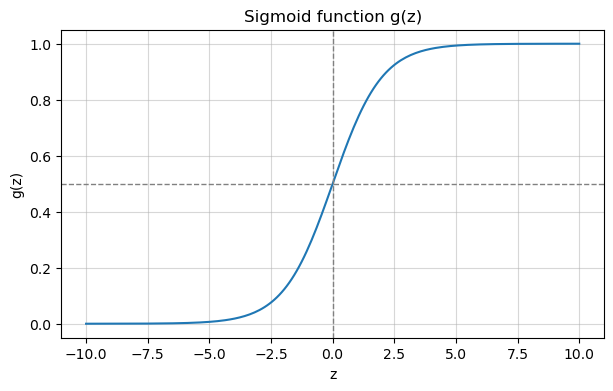

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_demo = np.linspace(-10, 10, 200)
plt.figure(figsize=(7,4))
plt.plot(z_demo, sigmoid(z_demo), color='#1f77b4')
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1)
plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sigmoid function g(z)')
plt.xlabel('z'); plt.ylabel('g(z)')
plt.grid(alpha=0.5)
plt.show()


## 5. The model hypothesis

$$h_\theta(x) = g(\theta_0 + \theta_1 x) = \frac{1}{1+e^{-(\theta_0+\theta_1 x)}}$$

Here $h_\theta(x)$ means: the **probability that the class is 1**, given $x$.

Final classification rule:

$$\hat{y} = \begin{cases}1 & h_\theta(x) \ge 0.5 \\ 0 & h_\theta(x) < 0.5\end{cases}$$

**Talking point:** 0.5 is the *default* decision threshold, but it isn't sacred. If false negatives are much more costly than false positives (e.g. missing a genuinely successful location), you might lower the threshold to 0.3 to be more "generous" about calling something a success — trading precision for recall. We'll touch on this again at the confusion-matrix step.

In [6]:
X = np.column_stack([np.ones(m), X_raw])   # add the column of 1's for theta0
y_col = y.reshape(-1,1)

def h(theta, X):
    return sigmoid(X @ theta)


## 6. Cost function — Cross-Entropy

We *can't* reuse the linear-regression cost function (mean squared error) here. Combined with the sigmoid, MSE becomes **non-convex** — it would have multiple local dips, and gradient descent could get stuck in one of them instead of finding the best fit.

Instead we use **Log Loss / Cross-Entropy**:

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y^{(i)}\log(h_\theta(x^{(i)})) + (1-y^{(i)})\log(1-h_\theta(x^{(i)}))\Big]$$

**Talking point — why this specific formula works so well:**
- If $y=1$ and the model predicts a probability near 1 → cost is close to 0 (good, small penalty).
- If $y=1$ and the model predicts a probability near 0 → cost blows up toward infinity (a *harsh* penalty for being confidently wrong).
- The mirror image happens when $y=0$.

This asymmetric, heavily-punishing-confident-mistakes behavior is exactly what pushes the model to be honest about uncertainty rather than confidently wrong.

In [7]:
def computeCost(theta, X, y, eps=1e-10):
    m = len(y)
    hx = h(theta, X)
    hx = np.clip(hx, eps, 1-eps)
    cost = -(1/m) * np.sum(y*np.log(hx) + (1-y)*np.log(1-hx))
    return cost

theta_init = np.zeros((2,1))
print('Initial cost with theta=[0,0]:', computeCost(theta_init, X, y_col))


Initial cost with theta=[0,0]: 0.6931471805599453


## 7. Gradient and the update rule (Gradient Descent)

The partial derivative of $J(\theta)$ with respect to $\theta_j$ has **exactly the same form** as in linear regression — one of the elegant side-effects of pairing cross-entropy with the sigmoid:

$$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big)x_j^{(i)}$$

Vectorized update rule:

$$\theta := \theta - \frac{\alpha}{m} X^T\big(h_\theta(X) - y\big)$$

where $\alpha$ is the learning rate.

**Talking point:** even though the *formula* looks identical to linear regression's gradient, $h_\theta(x)$ means something completely different now (a sigmoid-squashed probability instead of a raw linear prediction). It's a nice coincidence of the math, not a sign that the two models are secretly the same thing.

In [9]:
def gradientDescent(X, y, theta, alpha, iters):
    m = len(y)
    J_history = np.zeros(iters)
    for i in range(iters):
        hx = h(theta, X)
        grad = (1/m) * (X.T @ (hx - y))
        theta = theta - alpha * grad
        J_history[i] = computeCost(theta, X, y)
    return theta, J_history

alpha = 0.01
iters = 200000

theta_final, J_history = gradientDescent(X, y_col, theta_init.copy(), alpha, iters)
print('theta0 =', theta_final[0,0])
print('theta1 =', theta_final[1,0])
print('Final cost =', J_history[-1])


theta0 = -6.023022959796771
theta1 = 0.7986672962214075
Final cost = 0.4611891400035033


## 8. Cost curve during training

**Talking point:** watch the shape of this curve. It should drop quickly at first and then flatten out. If it's still dropping sharply at the last iteration, that's a sign we should train longer or raise `alpha`. If it's jittery / bouncing around instead of smoothly decreasing, `alpha` is probably too large.

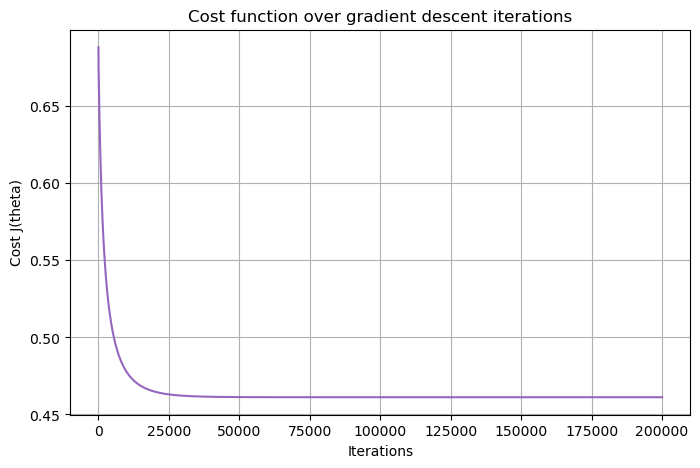

In [10]:
plt.figure(figsize=(8,5))
plt.plot(np.arange(iters), J_history, color='#9467bd')
plt.xlabel('Iterations')
plt.ylabel('Cost J(theta)')
plt.title('Cost function over gradient descent iterations')
plt.grid(alpha=1)
plt.show()


## 9. Decision boundary

The decision boundary is the point where $h_\theta(x) = 0.5$, i.e. where $\theta_0 + \theta_1 x = 0$:

$$x_{boundary} = -\frac{\theta_0}{\theta_1}$$

Any city with population above $x_{boundary}$ gets predicted as class 1; any city below it gets predicted as class 0.

**Talking point:** with a single feature, the "boundary" is just a vertical line/point. With two features it would be a line in 2D, with three features a plane in 3D, and so on — logistic regression always produces a *linear* boundary in the feature space (unless you engineer non-linear features like $x^2$ yourself).

Decision boundary at population = 7.5413 (x10,000) = 75,413 people


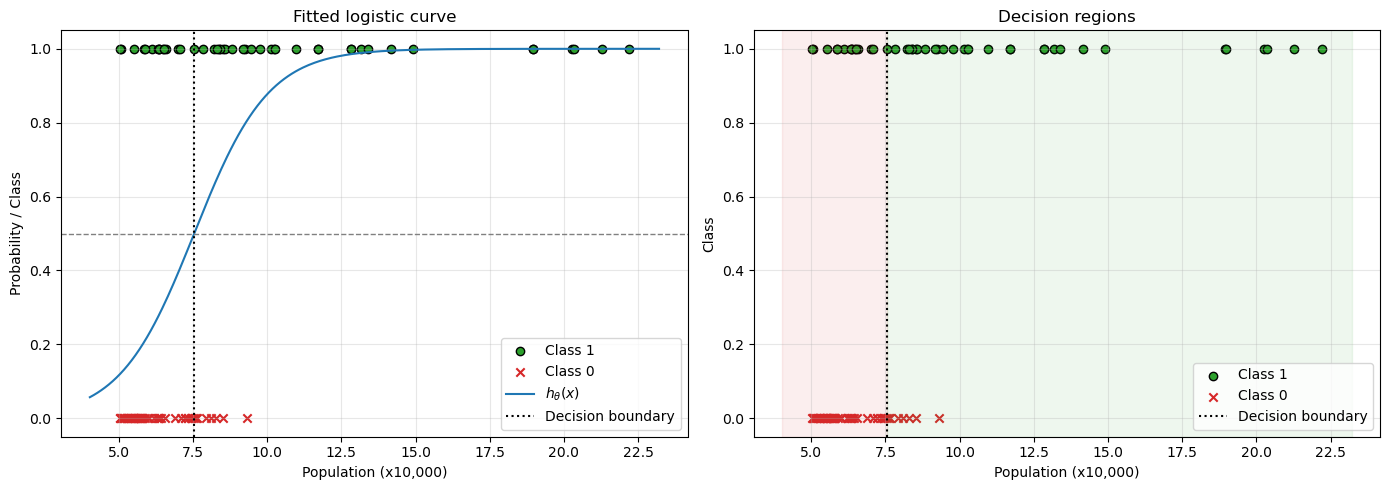

In [11]:
x_boundary = -theta_final[0,0] / theta_final[1,0]
print(f'Decision boundary at population = {x_boundary:.4f} (x10,000) = {x_boundary*10000:,.0f} people')

x_vals = np.linspace(X_raw.min()-1, X_raw.max()+1, 300)
prob_vals = sigmoid(theta_final[0,0] + theta_final[1,0]*x_vals)

fig, axes = plt.subplots(1, 2, figsize=(14,5))

axes[0].scatter(X_raw[y==1], np.ones(np.sum(y==1)), color='#2ca02c', label='Class 1', edgecolor='k')
axes[0].scatter(X_raw[y==0], np.zeros(np.sum(y==0)), color='#d62728', marker='x', label='Class 0')
axes[0].plot(x_vals, prob_vals, color='#1f77b4', label=r'$h_\theta(x)$')
axes[0].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0].axvline(x_boundary, color='black', linestyle=':', linewidth=1.5, label='Decision boundary')
axes[0].set_xlabel('Population (x10,000)'); axes[0].set_ylabel('Probability / Class')
axes[0].set_title('Fitted logistic curve'); axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(X_raw[y==1], y[y==1], color='#2ca02c', label='Class 1', edgecolor='k')
axes[1].scatter(X_raw[y==0], y[y==0], color='#d62728', marker='x', label='Class 0')
axes[1].axvspan(X_raw.min()-1, x_boundary, color='#d62728', alpha=0.08)
axes[1].axvspan(x_boundary, X_raw.max()+1, color='#2ca02c', alpha=0.08)
axes[1].axvline(x_boundary, color='black', linestyle=':', linewidth=1.5, label='Decision boundary')
axes[1].set_xlabel('Population (x10,000)'); axes[1].set_ylabel('Class')
axes[1].set_title('Decision regions'); axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Model accuracy and confusion matrix

**Talking point — beyond accuracy:** accuracy alone can be misleading (see the class-imbalance point back in section 2). The confusion matrix breaks the errors down into:
- **TP** (True Positive): predicted successful, actually successful
- **TN** (True Negative): predicted not successful, actually not successful
- **FP** (False Positive): predicted successful, actually *not* — a costly mistake if opening the branch is expensive
- **FN** (False Negative): predicted not successful, actually *was* — a missed opportunity

From there, **Precision** tells you "of the branches I predicted successful, how many really were" (useful when false positives are expensive), and **Recall** tells you "of the truly successful branches, how many did I catch" (useful when missed opportunities are expensive). **F1** balances the two.

In [12]:
y_pred = (h(theta_final, X) >= 0.5).astype(int).flatten()
y_true = y

accuracy = np.mean(y_pred == y_true) * 100
print(f'Accuracy = {accuracy:.2f}%')

TP = np.sum((y_pred==1)&(y_true==1))
TN = np.sum((y_pred==0)&(y_true==0))
FP = np.sum((y_pred==1)&(y_true==0))
FN = np.sum((y_pred==0)&(y_true==1))

print(f'TP={TP}  FN={FN}')
print(f'FP={FP}  TN={TN}')

precision = TP / (TP+FP) if (TP+FP) else 0
recall = TP / (TP+FN) if (TP+FN) else 0
f1 = 2*precision*recall/(precision+recall) if (precision+recall) else 0
print(f'Precision = {precision:.3f}, Recall = {recall:.3f}, F1-score = {f1:.3f}')


Accuracy = 77.32%
TP=30  FN=15
FP=7  TN=45
Precision = 0.811, Recall = 0.667, F1-score = 0.732


## 11. Prediction

Now that we have a trained model, we can use it to estimate the probability that a branch in a *new* city will succeed, plus the final decision (0 or 1), simply by plugging into:

$$h_\theta(x) = g(\theta_0 + \theta_1 x)$$

**Talking point:** notice we return both the raw probability *and* the hard class. In a real business setting, the probability itself is often more useful than the binary label — a 51% and a 99% both round to "Class 1," but they represent very different levels of confidence, and a decision-maker would probably want to know which one they're dealing with.

In [11]:
def predict(population_in_10k):
    x = np.array([1, population_in_10k])
    prob = sigmoid(x @ theta_final.flatten())
    cls = int(prob >= 0.5)
    return prob, cls

for pop in [3.5, 7.0, 12.0]:
    prob, cls = predict(pop)
    label = 'Successful' if cls==1 else 'Not successful'
    print(f'City with population {pop*10000:,.0f} -> P(success) = {prob:.3f} -> Prediction: {label}')


City with population 35,000 -> P(success) = 0.038 -> Prediction: Not successful
City with population 70,000 -> P(success) = 0.394 -> Prediction: Not successful
City with population 120,000 -> P(success) = 0.972 -> Prediction: Successful


## 12. Summary & discussion

| Step | Description |
|---|---|
| Hypothesis | $h_\theta(x) = g(\theta_0+\theta_1 x) = \dfrac{1}{1+e^{-(\theta_0+\theta_1 x)}}$ |
| Cost function | $J(\theta) = -\dfrac{1}{m}\sum \big[y\log(h_\theta(x)) + (1-y)\log(1-h_\theta(x))\big]$ |
| Update rule | $\theta := \theta - \dfrac{\alpha}{m}X^T(h_\theta(X)-y)$ |
| Decision rule | $\hat{y}=1$ if $h_\theta(x)\ge 0.5$, else $\hat{y}=0$ |
| Decision boundary | $x = -\theta_0/\theta_1$ |
| Result | A threshold that classifies any new city as "successful" or not, based only on its population |

**Things worth trying next / discussion points:**
- **Change the threshold.** Go back to the Excel file (cell that defines the threshold), change it, re-run — you'll see both the labels *and* the decision boundary shift, since we've redefined what "success" means.
- **Add more features.** Right now we only use population. Real business decisions would also weigh local competition, rent cost, foot traffic, etc. Logistic regression handles multiple features the same way — just add more columns to $X$ and more $\theta$'s.
- **Compare against `scikit-learn`.** It's a good exercise to re-fit this same data with `sklearn.linear_model.LogisticRegression` and check that the learned boundary roughly matches what we got from scratch — it's a nice sanity check on the from-scratch implementation.
- **Regularization.** With more features, overfitting becomes a real risk. Adding an L2 penalty term to $J(\theta)$ (ridge-style) is the natural next topic once you go beyond one variable.